In [1]:
from math import pi, cos, sin
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = AerSimulator()
SHOTS = 100

## Circuit 1: 0 occurs more frequently (theta = pi/3)
P(0) = cos^2(pi/6) = 75%, P(1) = sin^2(pi/6) = 25%.
So 0 should occur more frequently, about 75 zeros and 25 ones out of 100 shots.

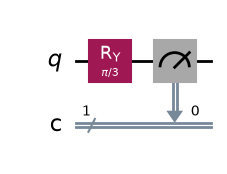

Predicted: P(0) = 0.75  P(1) = 0.25


In [2]:
theta1 = pi/3
qc1 = QuantumCircuit(1, 1, name="Circuit 1")
qc1.ry(theta1, 0)
qc1.measure(0, 0)

display(qc1.draw("mpl"))
print("Predicted: P(0) =", round(cos(theta1/2)**2, 3), " P(1) =", round(sin(theta1/2)**2, 3))

Circuit 1 results: {'0': 76, '1': 24}


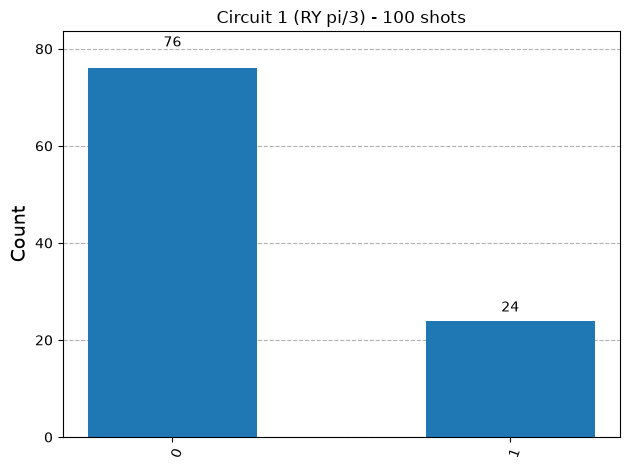

In [3]:
counts1 = sim.run(qc1, shots=SHOTS).result().get_counts()
print("Circuit 1 results:", counts1)
display(plot_histogram(counts1, title="Circuit 1 (RY pi/3) - 100 shots"))

## Circuit 2 (Bonus): 1 occurs more frequently (theta = 2*pi/3)
P(0) = cos^2(pi/3) = 25%, P(1) = sin^2(pi/3) = 75%.
So 1 should occur more frequently, about 25 zeros and 75 ones.

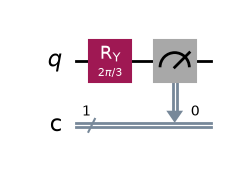

Predicted: P(0) = 0.25  P(1) = 0.75


In [5]:
theta2 = 2*pi/3
qc2 = QuantumCircuit(1, 1, name="Circuit 2")
qc2.ry(theta2, 0)
qc2.measure(0, 0)

display(qc2.draw("mpl"))
print("Predicted: P(0) =", round(cos(theta2/2)**2, 3), " P(1) =", round(sin(theta2/2)**2, 3))

Circuit 2 results: {'1': 72, '0': 28}


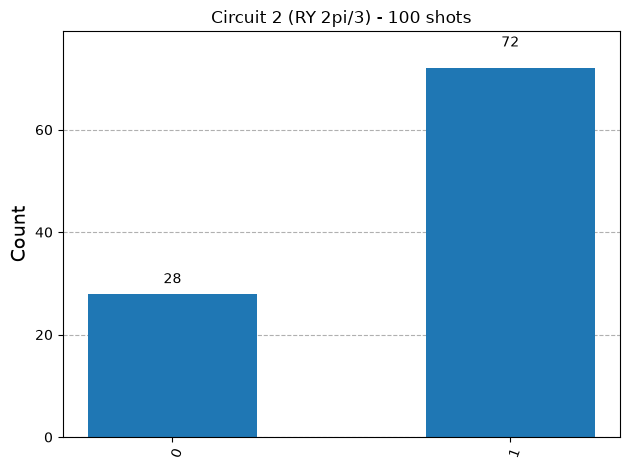

In [6]:
counts2 = sim.run(qc2, shots=SHOTS).result().get_counts()
print("Circuit 2 results:", counts2)
display(plot_histogram(counts2, title="Circuit 2 (RY 2pi/3) - 100 shots"))

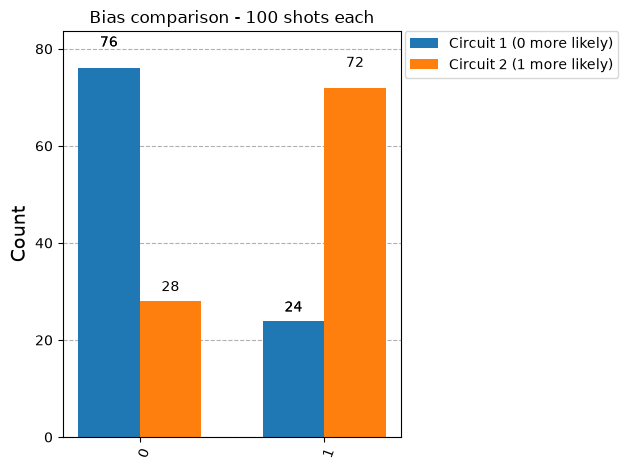

In [7]:
plot_histogram([counts1, counts2],
               legend=["Circuit 1 (0 more likely)", "Circuit 2 (1 more likely)"],
               title="Bias comparison - 100 shots each")

theta=pi/6         predicted P(0)=0.93  actual: {'0': 90, '1': 10}
theta=pi/3         predicted P(0)=0.75  actual: {'0': 78, '1': 22}
theta=pi/2 (fair)  predicted P(0)=0.50  actual: {'0': 44, '1': 56}
theta=2pi/3        predicted P(0)=0.25  actual: {'1': 85, '0': 15}
theta=5pi/6        predicted P(0)=0.07  actual: {'1': 92, '0': 8}


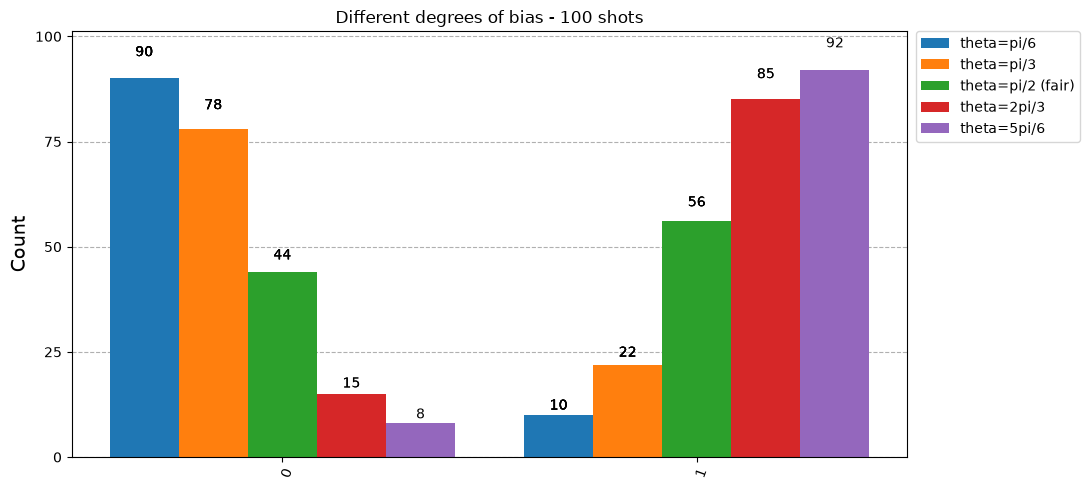

In [8]:
angles = {"pi/6": pi/6, "pi/3": pi/3, "pi/2 (fair)": pi/2, "2pi/3": 2*pi/3, "5pi/6": 5*pi/6}
all_counts = {}
for label, th in angles.items():
    qc = QuantumCircuit(1, 1)
    qc.ry(th, 0)
    qc.measure(0, 0)
    c = sim.run(qc, shots=SHOTS).result().get_counts()
    all_counts[f"theta={label}"] = c
    print(f"theta={label:12s} predicted P(0)={cos(th/2)**2:.2f}  actual: {c}")

plot_histogram(list(all_counts.values()), legend=list(all_counts.keys()),
               title="Different degrees of bias - 100 shots", figsize=(11, 5))

## Comparison: Prediction vs Actual
- Circuit 1: Predicted about 75% '0' / 25% '1'. Actual: {'0': __, '1': __}. Close to prediction; the small difference is due to randomness in 100 shots.
- Circuit 2: Predicted about 25% '0' / 75% '1'. Actual: {'0': __, '1': __}. Again close to the prediction.

## How the gates changed the distribution
Starting from |0>, a plain measurement always gives 0. An H gate gives 50/50. The RY(theta) gate rotates the qubit by a chosen angle: a small theta keeps the state near |0> (0 is more likely), theta = pi/2 gives a fair coin, and a larger theta moves it toward |1> (1 is more likely). Changing the angle changes the degree of bias.